<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Exploratory Data Analysis | Understanding Developer Survey Trends**
**IBM Skills Network guided lab | Personalized portfolio edition**


### Project Overview
A survey can tell us much more than how many people answered each question. By looking at responses together, we can begin to understand how developers work, what they use, and how they feel about their jobs. In this notebook, I explore a Stack Overflow developer survey using Python. I look at job satisfaction, professional coding experience, remote-work arrangements, programming languages, and education.

**Question guiding the analysis:** What patterns can we see in developers' experiences and working lives, and where should we be careful about drawing conclusions?

**My approach:** Get familiar with the data → Check missing answers → Explore experience and satisfaction → Compare working arrangements → Look at programming languages and education → Save the results.

**Tools and skills:** Python, Pandas, Matplotlib, Seaborn, exploratory data analysis (EDA), grouping, cross-tabulation, and data visualization.

*This is a guided IBM Skills Network exercise. I have kept its original learning structure and added my own explanations to make the analysis easier to follow.*

Estimated time needed: **30** minutes


### Objectives


In this lab, you will perform the following:
- Examine the structure of a dataset.
- Handle missing values effectively.
- Conduct summary statistics on key columns.
- Analyze employment status, job satisfaction, programming language usage, and trends in remote work.

### Hands on Lab


#### Step 1: Install and Import Libraries


Install the necessary libraries for data manipulation and visualization.


In [8]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Step 2: Load and Preview the Dataset
Before looking for patterns, I want to see what the data actually contains. A quick preview helps me understand what each row represents and which questions were asked.

In [9]:
# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Set pandas option to display all columns
pd.set_option('display.max_columns', None)

# Display the first few rows of the dataset
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,YearsCode,YearsCodePro,DevType,OrgSize,PurchaseInfluence,BuyNewTool,BuildvsBuy,TechEndorse,Country,Currency,CompTotal,LanguageHaveWorkedWith,LanguageWantToWorkWith,LanguageAdmired,DatabaseHaveWorkedWith,DatabaseWantToWorkWith,DatabaseAdmired,PlatformHaveWorkedWith,PlatformWantToWorkWith,PlatformAdmired,WebframeHaveWorkedWith,WebframeWantToWorkWith,WebframeAdmired,EmbeddedHaveWorkedWith,EmbeddedWantToWorkWith,EmbeddedAdmired,MiscTechHaveWorkedWith,MiscTechWantToWorkWith,MiscTechAdmired,ToolsTechHaveWorkedWith,ToolsTechWantToWorkWith,ToolsTechAdmired,NEWCollabToolsHaveWorkedWith,NEWCollabToolsWantToWorkWith,NEWCollabToolsAdmired,OpSysPersonal use,OpSysProfessional use,OfficeStackAsyncHaveWorkedWith,OfficeStackAsyncWantToWorkWith,OfficeStackAsyncAdmired,OfficeStackSyncHaveWorkedWith,OfficeStackSyncWantToWorkWith,OfficeStackSyncAdmired,AISearchDevHaveWorkedWith,AISearchDevWantToWorkWith,AISearchDevAdmired,NEWSOSites,SOVisitFreq,SOAccount,SOPartFreq,SOHow,SOComm,AISelect,AISent,AIBen,AIAcc,AIComplex,AIToolCurrently Using,AIToolInterested in Using,AIToolNot interested in Using,AINextMuch more integrated,AINextNo change,AINextMore integrated,AINextLess integrated,AINextMuch less integrated,AIThreat,AIEthics,AIChallenges,TBranch,ICorPM,WorkExp,Knowledge_1,Knowledge_2,Knowledge_3,Knowledge_4,Knowledge_5,Knowledge_6,Knowledge_7,Knowledge_8,Knowledge_9,Frequency_1,Frequency_2,Frequency_3,TimeSearching,TimeAnswering,Frustration,ProfessionalTech,ProfessionalCloud,ProfessionalQuestion,Industry,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States of America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I have never visited Stack Overflow or the Sta...,NaN,NaN,NaN,NaN,NaN,Yes,Very favorable,Increase productivity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,20,17,"Developer, full-stack",NaN,NaN,NaN,NaN,NaN,United Kingdom of Great Britain and Northern I...,NaN,NaN,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Bash/Shell (all shells);Go;HTML/CSS;Java;JavaS...,Dynamodb;MongoDB;PostgreSQL,PostgreSQL,PostgreSQL,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Amazon Web Services (AWS);Heroku;Netlify,Express;Next.js;Node.js;React,Express;Htmx;Node.js;React;Remix,Express;Node.js;React,NaN,NaN,NaN,NaN,NaN,NaN,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,Docker;Homebrew;Kubernetes;npm;Vite;Webpack,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,PyCharm;Visual Studio Code;WebStorm,MacOS;Windows,MacOS,NaN,NaN,NaN,Microsoft Teams;Slack,Slack,Slack,NaN,NaN,NaN,Stack Overflow for Teams (private knowledge sh...,Multiple times per day,Yes,Multiple times per day,Quickly finding code solutions;Finding reliabl...,"Yes, definitely","No, and I don't plan to",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Yes,Individual contributor,17.0,Agree,Disagree,Agree,Agree,Agree,Neither agree nor disa

Here, each row represents a survey response. Columns such as `Employment`, `RemoteWork`, and `JobSat`contain different parts of that respondent's experience. The first few rows are only a preview, not a summary of everyone in the survey.

#### Step 3: Handling Missing Data


Identify and manage missing values in critical columns such as `Employment`, `JobSat`, and `RemoteWork`. Not every survey participant answers every question. That matters because missing responses can change the picture we get from the data.

In [10]:
## Write your code here
print(df[['Employment', 'JobSat', 'RemoteWork']].isnull().sum())

df['Employment'] = df['Employment'].fillna(df['Employment'].mode()[0])
df['JobSat'] = df['JobSat'].fillna(df['JobSat'].mode()[0])
df['RemoteWork'] = df['RemoteWork'].fillna(df['RemoteWork'].mode()[0])

Employment        0
JobSat        36311
RemoteWork    10631
dtype: int64

**What the saved output tells us:** Employment has no missing responses, while JobSat has 36,311 and RemoteWork has 10,631 before filling. That's a substantial amount of missing information, especially for job satisfaction.

**Something to keep in mind:** Replacing missing answers with the most common answer is convenient for practice, but it can make that answer appear more popular than it really is. We'll interpret later charts with that limitation in mind.

#### Step 4: Analysis of Experience and Job Satisfaction


Analyze the relationship between years of professional coding experience (`YearsCodePro`) and job satisfaction (`JobSat`). Summarize `YearsCodePro` and calculate median satisfaction scores based on experience ranges.

- Create experience ranges for `YearsCodePro` (e.g., `0-5`, `5-10`, `10-20`, `>20` years).
- Calculate the median `JobSat` for each range.
- Visualize the relationship using a bar plot or similar visualization.

Calculated Medians from JobSatPoints_1: ExperienceRange
0-5       5.0
5-10     10.0
10-20    10.0
>20      10.0
Name: JobSatPoints_1, dtype: float64

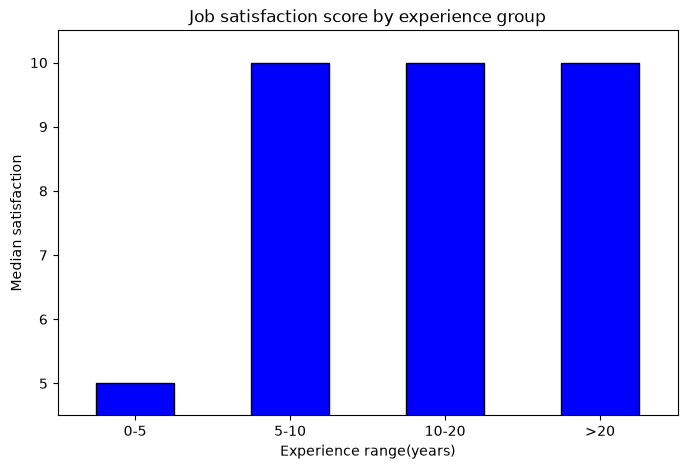

In [14]:
## Write your code here
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'], errors='coerce').fillna(0)

def experience_bucket(years):
    if years <= 5: 
        return '0-5'
    elif years <= 10: 
        return '5-10'
    elif years <= 20: 
        return '10-20'
    else: 
        return '>20'

df['ExperienceRange'] = df['YearsCodePro'].apply(experience_buckets)

median_sat = df.groupby('ExperienceRange')['JobSatPoints_1'].median().reindex(['0-5', '5-10', '10-20', '>20'])
print("Calculated Medians from JobSatPoints_1:", median_sat)


plt.figure(figsize=(8, 5))
median_sat.plot(kind='bar', color='blue', edgecolor='black')
plt.title('Job satisfaction score by experience group')
plt.ylabel('Median satisfaction')
plt.xlabel('Experience range(years)')
plt.ylim(median_sat.min() - 0.5, median_sat.max() + 0.5) 
plt.xticks(rotation=0)
plt.show()

**Saved result:** The median JobSatPoints_1 values are 5 for 0-5 years and 10 for each of the other three groups. This is a descriptive pattern in the saved run,not proof that more experience causes higher satisfaction.

**Important caveat:** The code converts unrecognized or missing experience values to zero. That can put respondents with unknown experience into the 0-5 group and affect its median. The original function name also contained a typo, which I've corrected so the calculation can run.

#### Step 5: Visualize Job Satisfaction


Use a count plot to show the distribution of `JobSat` values. This provides insights into the overall satisfaction levels of respondents.


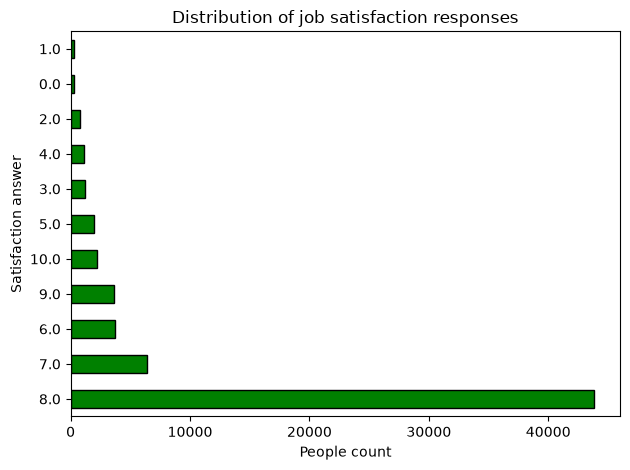

In [15]:
## Write your code here
df['JobSat'].value_counts().plot(kind='barh', color='green', edgecolor='black')
plt.title('Distribution of job satisfaction responses')
plt.ylabel('Satisfaction answer')
plt.xlabel('People count')
plt.tight_layout()
plt.show()

Now I'll look at the overall distribution of the JobSat responses. A horizontal bar chart makes it easier to compare the different answer categories at a glance.

The longer a bar, the more responses appear in that category. But because missing JobSat entries were filled with the most common response earlier, the chart does not show only answers that respondents actually provided. It includes those replacements too.

#### Step 6: Analyzing Remote Work Preferences by Job Role


Analyze trends in remote work based on job roles. Use the `RemoteWork` and `Employment` columns to explore preferences and examine if specific job roles prefer remote work more than others.

- Use a count plot to show remote work distribution.
- Cross-tabulate remote work preferences by employment type (e.g., full-time, part-time) and job roles.

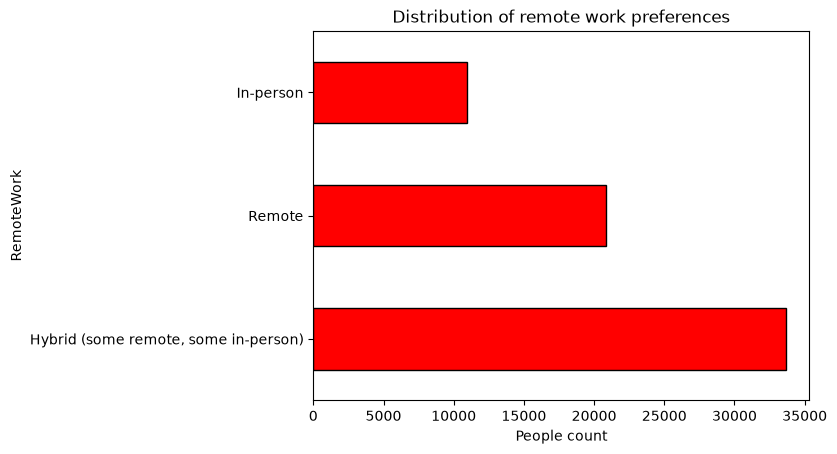

RemoteWork                                          Hybrid (some remote, some in-person)  \
Employment                                                                                 
Employed, full-time                                                                17296   
Employed, full-time;Employed, part-time                                               85   
Employed, full-time;Independent contractor, fre...                                  1330   
Employed, full-time;Independent contractor, fre...                                    80   
Employed, full-time;Independent contractor, fre...                                     0   
...                                                                                  ...   
Student, full-time;Student, part-time;Employed,...                                     4   
Student, full-time;Student, part-time;Retired                                          2   
Student, part-time                                                              

In [16]:
## Write your code here
df['RemoteWork'].value_counts().plot(kind='barh', color='red', edgecolor='black')
plt.title('Distribution of remote work preferences')
plt.xlabel('People count')
plt.show()

cross_tab_remote = pd.crosstab(df['Employment'], df['RemoteWork'])
print(cross_tab_remote)

Remote, hybrid, and in-person work are important parts of a developer's working life. First, I'll count the responses in each arrangement. Then I'll compare those arrangements across employment categories.

A cross-tabulation is simply a table showing how two categories overlap. For example, it can tell us how many full-time respondents reported remote or hybrid work.

**One detail matters here:** Employment includes combinations such as full-time work plus contracting. These are employment categories, not individual job titles. Also, the RemoteWork field describes reported arrangements; it doesn't directly measure what people prefer. Missing remote-work answers were filled earlier, so the counts should be treated cautiously.

#### Step 7: Analyzing Programming Language Trends by Region


Analyze the popularity of programming languages by region. Use the `LanguageHaveWorkedWith` column to investigate which languages are most used in different regions.

- Filter data by country or region.
- Visualize the top programming languages by region with a bar plot or heatmap.

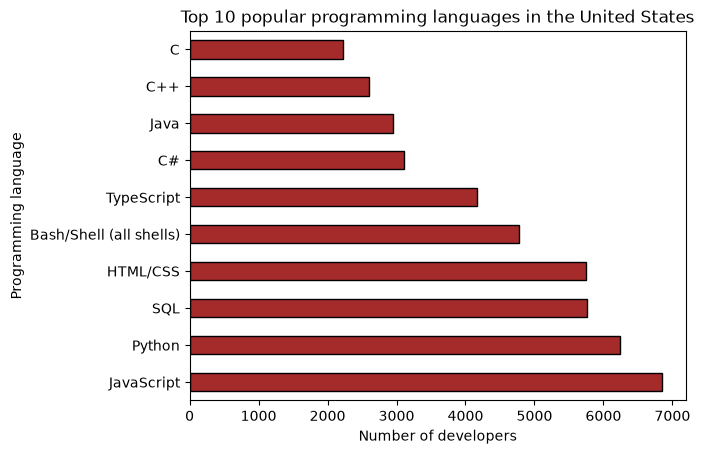

In [18]:
## Write your code here
us_data = df[df['Country'] == 'United States of America']
top_languages = us_data['LanguageHaveWorkedWith'].str.split(';').explode().value_counts().head(10)

top_languages.plot(kind='barh', color='brown', edgecolor='black')
plt.title('Top 10 popular programming languages in the United States')
plt.ylabel('Programming language')
plt.xlabel('Number of developers')
plt.show()

For this section, I focused on survey participants from the United States. Respondents can list several languages in one answer, separated by semicolons. The code splits those answers into individual languages, counts how often each one appears, and plots the ten most frequently mentioned.

**How to read this chart:** Each bar represents the number of US survey responses mentioning a language. One person may contribute to several bars, so the totals should not be added together to estimate the number of developers. These are reported technologies used, not necessarily a measure of job-market demand.

#### Step 8: Correlation Between Experience and Satisfaction


Examine how years of experience (`YearsCodePro`) correlate with job satisfaction (`JobSatPoints_1`). Use a scatter plot to visualize this relationship.


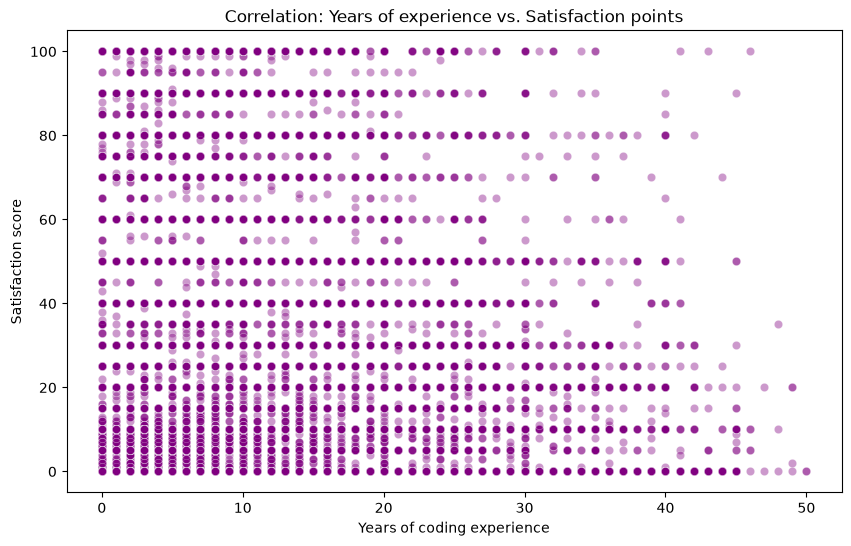

In [19]:
## Write your code here
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='YearsCodePro', y='JobSatPoints_1', alpha=0.4, color='purple')
plt.title('Correlation: Years of experience vs. Satisfaction points')
plt.ylabel('Satisfaction score')
plt.xlabel('Years of coding experience')
plt.show()

The earlier bar chart compared median satisfaction across broad experience groups. Here, a scatter plot lets me look at the relationship at the individual-response level.

**Each dot represents a pair of values:** years of professional coding experience and a satisfaction score. This helps me see whether scores generally rise, fall, or vary widely across experience levels.

**A careful interpretation:** A scatter plot is useful for spotting a possible relationship, but it doesn't calculate a correlation coefficient on its own or show causation. Missing experience values converted to zero may also create an artificial cluster at the start of the horizontal axis.

#### Step 9: Educational Background and Employment Type


Explore how educational background (`EdLevel`) relates to employment type (`Employment`). Use cross-tabulation and visualizations to understand if higher education correlates with specific employment types.


Employment                                          Employed, full-time  \
EdLevel                                                                   
Associate degree (A.A., A.S., etc.)                                1059   
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                      16806   
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                   11011   
Primary/elementary school                                           160   
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                     2073   
Secondary school (e.g. American high school, Ge...                 1460   
Some college/university study without earning a...                 3579   
Something else                                                      377   

Employment                                          Employed, full-time;Employed, part-time  \
EdLevel                                                                                       
Associate degree (A.A., A.S., etc.)                        

/tmp/ipykernel_1200/1639407896.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

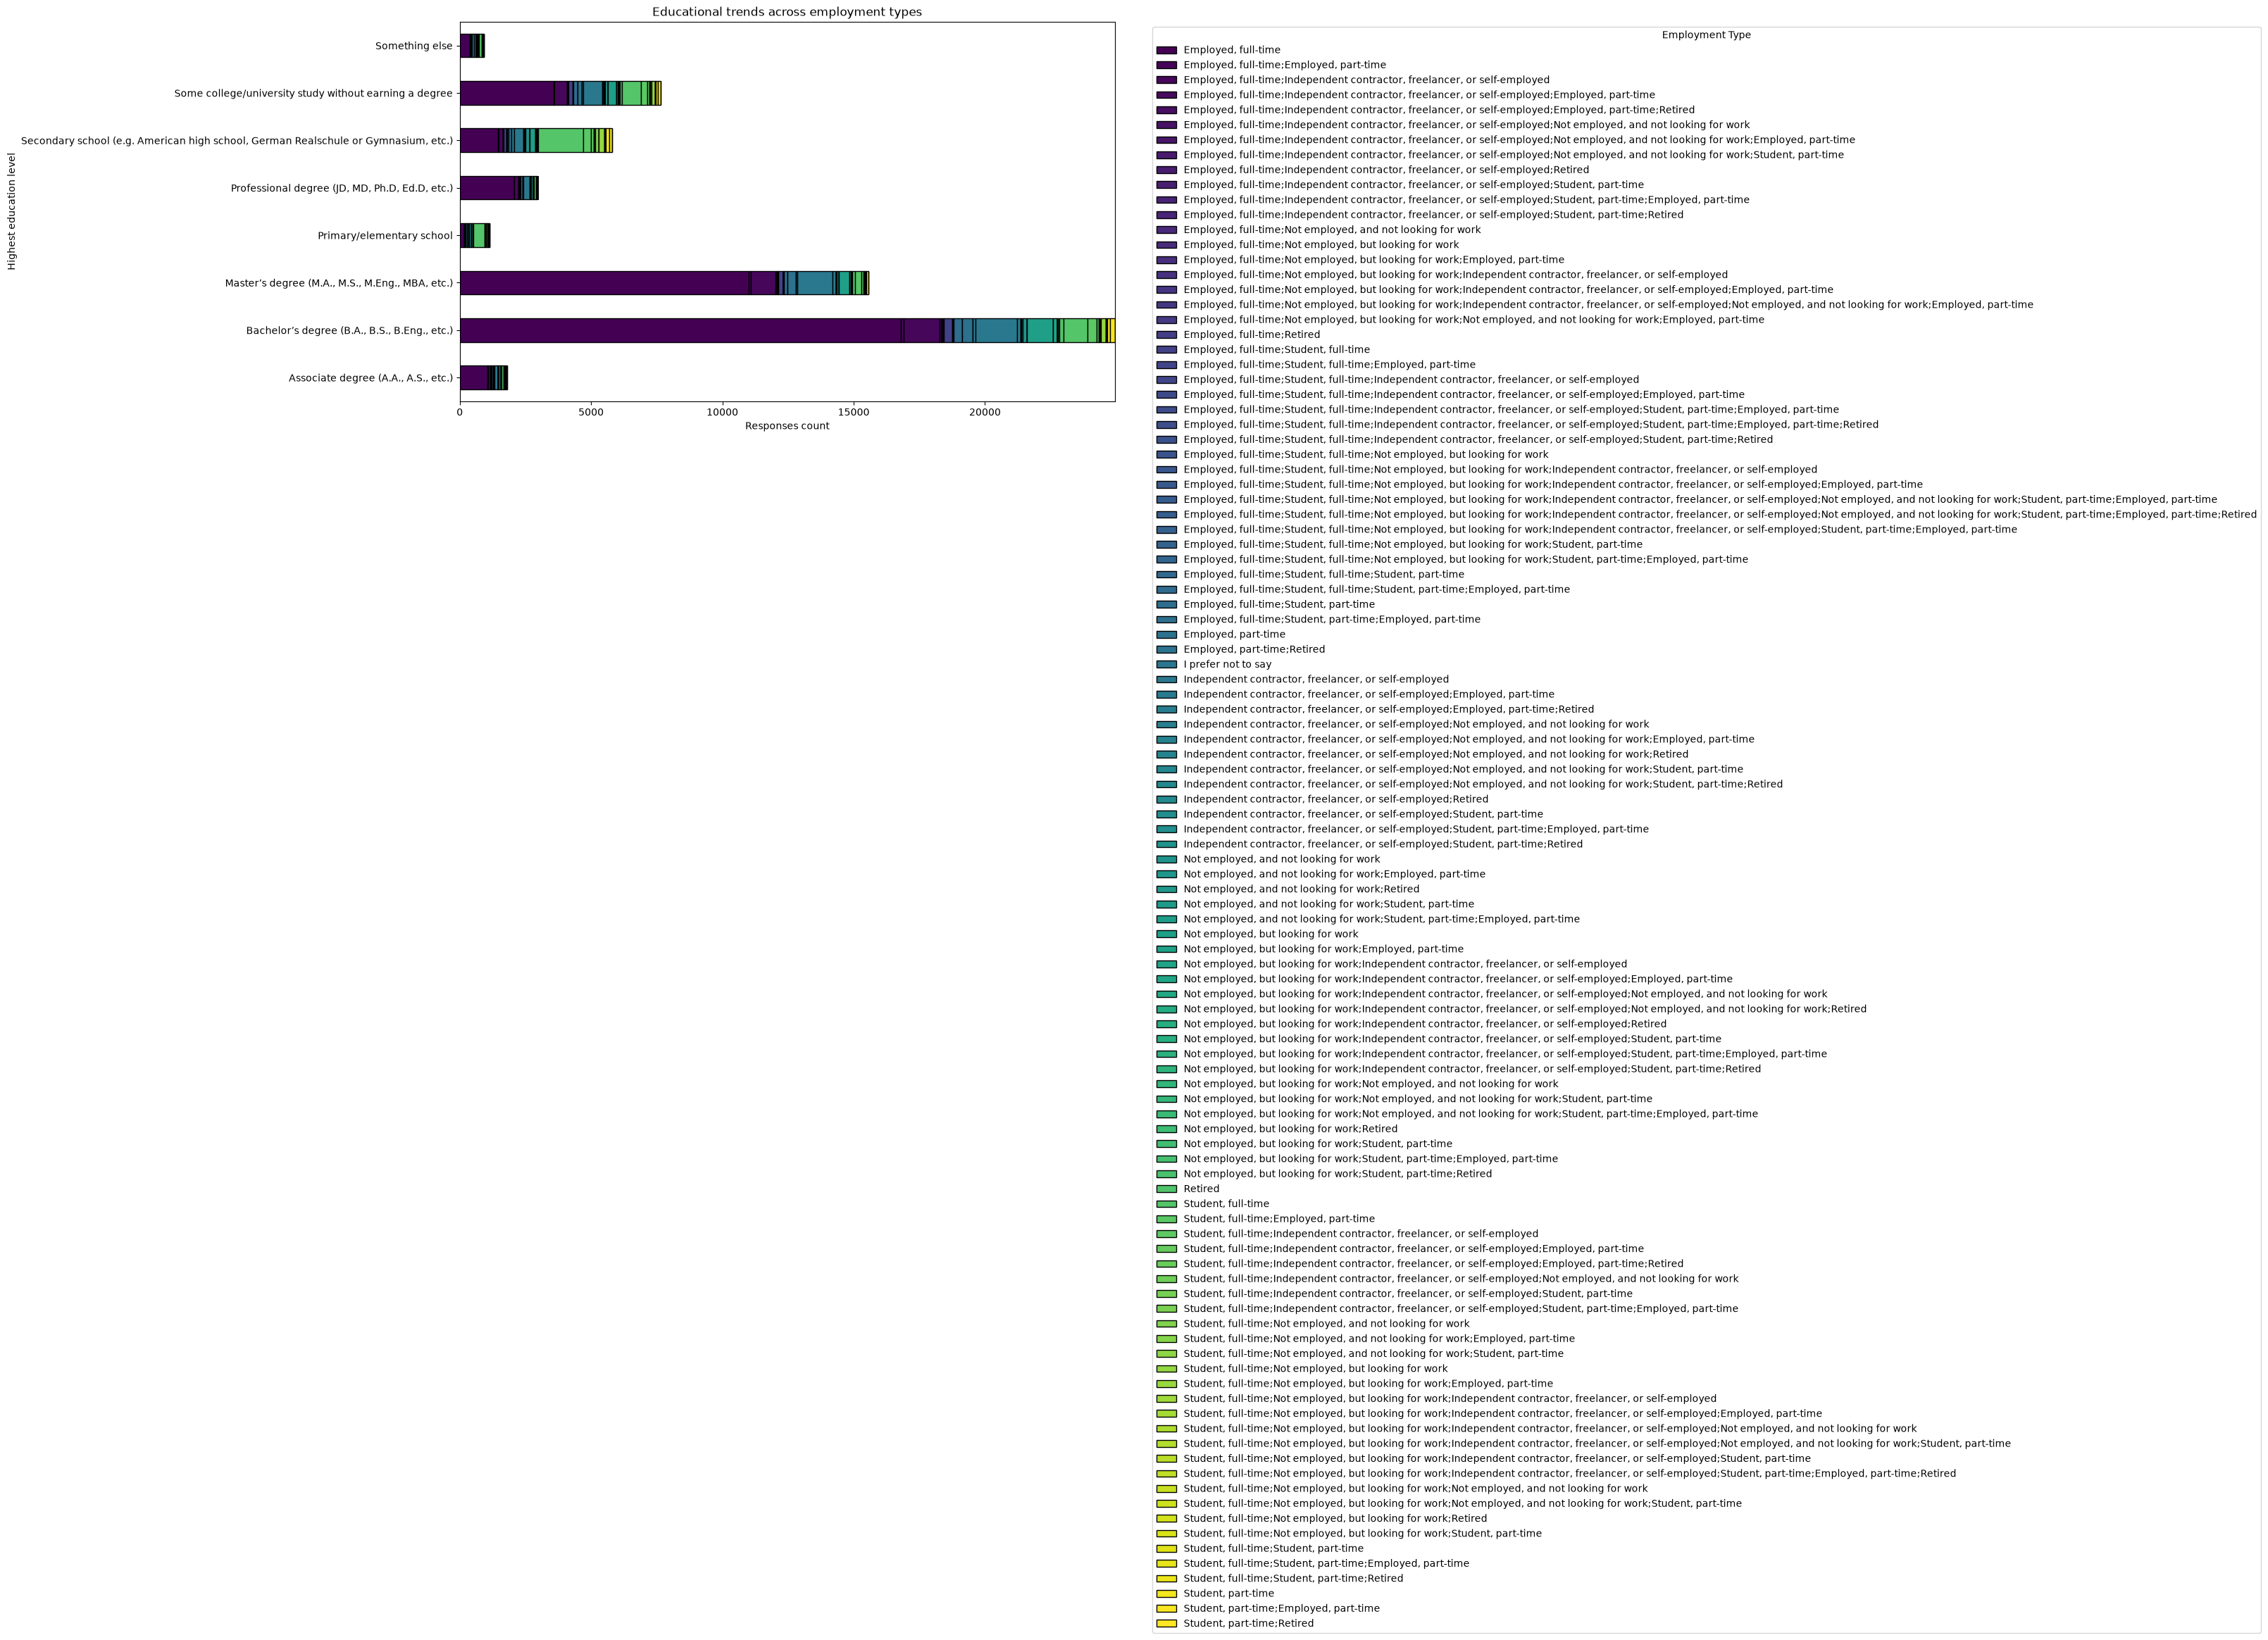

In [21]:
## Write your code here
employment_table = pd.crosstab(df['EdLevel'], df['Employment'])
print(employment_table)

employment_table.plot(kind='barh', stacked=True, figsize=(12, 7), colormap='viridis', edgecolor='black')
plt.title('Educational trends across employment types')
plt.ylabel('Highest education level')
plt.xlabel('Responses count')
plt.legend(title='Employment Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Finally, I'll explore whether respondents with different education levels report different employment categories.The cross-tabulation counts responses for each education-and-employment combination. The stacked chart then puts those counts side by side.

This is a useful starting point, but larger groups will naturally tend to have larger counts. To compare the likelihood of an employment category across education levels more fairly, I'd want to examine percentages within each education group rather than rely on raw counts alone.

#### Step 10: Save the Cleaned and Analyzed Dataset


After your analysis, save the modified dataset for further use or sharing.


In [23]:
## Write your code here
df.to_csv('final_survey_data.csv', index=False)
print("Dataset successfully saved")

Dataset successfully saved

### Summary 


In this revised lab, you:

- Loaded and explored the structure of the dataset.
- Handled missing data effectively.
- Analyzed key variables, including working hours, job satisfaction, and remote work trends.
- Investigated programming language usage by region and examined the relationship between experience and satisfaction.
- Used cross-tabulation to understand educational background and employment type.

### Key Findings
- The saved analysis shows substantial missingness in job satisfaction and remote-work fields. Filling these values makes plotting easier but also changes the distribution.
- Median satisfaction differs between the 0-5 year experience group and the other experience groups in the saved results. This deserves further checking because unknown experience values were assigned zero.
- Cross-tabulations help describe how reported working arrangements and employment categories overlap, without establishing preferences or causes.
- Splitting multi-select language responses lets us count mentions of individual programming languages in US survey responses.
- Education and employment can be compared, but percentages would make differences between group sizes easier to interpret.

### Limitations and Next Steps
This is an exploratory exercise, so the findings describe survey responses rather than the entire developer workforce. Survey participation may not be representative. Missing answers, mode imputation, and assigning unknown experience to zero can affect the results.

If I continued this project, I would compare results before and after imputation, retain missing experience as unknown, use within-group percentages for education comparisons, and calculate a suitable association measure before describing a correlation.

### Skills Demonstrated
- Data preparation: Checking and filling missing values, converting data types, and creating experience groups.
- Exploratory analysis: Frequency counts, medians, grouped summaries, and cross-tabulations.
- Visualization: Bar charts, stacked charts, and scatter plots using Pandas, Matplotlib, and Seaborn.
- Communication: Explaining findings in everyday language and acknowledging where the evidence is limited.

*Attribution: Original lab materials and learning workflow belong to IBM Skills Network. Additional portfolio explanations and interpretation have been added. The original saved outputs have not been rerun.*

Copyright © IBM Corporation. All rights reserved.
